# Прогноз дощу: Random Forest

## 1. Імпорти та дані

In [1]:
import gc
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    make_scorer, fbeta_score, average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score, accuracy_score,
    classification_report, ConfusionMatrixDisplay,
)

from data_prep import *

SEED = globals().get("SEED", 42)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

In [2]:
df = load_clean()
train, gap, test = split_train_test(df)
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)

X_train, y_train = get_x_y(train)
X_test, y_test = get_x_y(test)
X_train, y_train = X_train.reset_index(drop=True), pd.Series(y_train).reset_index(drop=True)
X_test, y_test = X_test.reset_index(drop=True), pd.Series(y_test).reset_index(drop=True)
cv = list(time_cv_splits(train["Date"]))

print(f"Train: {X_train.shape} | gap: {gap.shape} | test: {X_test.shape}")
print(f"Частка дощових днів: train {y_train.mean():.3f}, test {y_test.mean():.3f}")

Train: (124858, 21) | gap: (49, 23) | test: (17286, 21)
Частка дощових днів: train 0.223, test 0.232


## 2. Налаштування та допоміжні функції

In [3]:
N_JOBS = 2
SEARCH_TREES = 150
N_ITER = 8
MIN_PRECISION = 0.40

F2 = make_scorer(fbeta_score, beta=2, zero_division=0)


def cv_run(model, X, perm=False):
    probas, perms, pr = [], [], []
    for i, (tr, va) in enumerate(cv):
        m = clone(model).fit(X.iloc[tr], y_train.iloc[tr])
        p = m.predict_proba(X.iloc[va])[:, 1]
        probas.append(p)
        pr.append(average_precision_score(y_train.iloc[va], p))
        if perm:
            idx = np.random.RandomState(SEED + i).choice(len(va), size=min(5000, len(va)), replace=False)
            r = permutation_importance(m, X.iloc[va].iloc[idx], y_train.iloc[va].iloc[idx],
                                       scoring="average_precision", n_repeats=2,
                                       random_state=SEED, n_jobs=1)
            perms.append(r.importances_mean)
        del m
        gc.collect()
    out = {
        "oof_proba": np.concatenate(probas),
        "oof_y": np.concatenate([y_train.iloc[va].to_numpy() for _, va in cv]),
        "pr_auc": float(np.mean(pr)),
    }
    if perm:
        out["perm"] = pd.DataFrame(perms, columns=X.columns)
    return out


def neutral_values(cols):
    return {c: (X_train[c].median() if pd.api.types.is_numeric_dtype(X_train[c]) else X_train[c].mode().iloc[0])
            for c in cols}


def neutralize(X, cols):
    if not cols:
        return X
    return X.assign(**neutral_values(cols))


def choose_threshold(y, proba, min_precision=MIN_PRECISION):
    rows = []
    for t in np.round(np.arange(0.10, 0.81, 0.01), 2):
        pred = proba >= t
        tp = (pred & (y == 1)).sum()
        prec = tp / max(pred.sum(), 1)
        rec = tp / y.sum()
        f2 = 5 * prec * rec / (4 * prec + rec) if (prec + rec) > 0 else 0
        rows.append({"threshold": t, "precision": prec, "recall": rec, "f2": f2})
    table = pd.DataFrame(rows)
    ok = table[table["precision"] >= min_precision]
    best = ok.sort_values(["recall", "f2"], ascending=False).iloc[0] if len(ok) else table.sort_values("f2").iloc[-1]
    return float(best["threshold"]), table


def test_metrics(proba, thr):
    pred = (proba >= thr).astype(int)
    return {"threshold": thr,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred, zero_division=0),
            "F2": fbeta_score(y_test, pred, beta=2, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, proba),
            "PR-AUC": average_precision_score(y_test, proba)}

## 3. Підбір гіперпараметрів

In [4]:
pipe = Pipeline([
    ("prep", build_preprocessor()),
    ("rf", RandomForestClassifier(n_estimators=SEARCH_TREES, max_samples=0.5,
                                  random_state=SEED, n_jobs=N_JOBS)),
])
param_dist = {
    "rf__max_depth": [10, 15],
    "rf__min_samples_leaf": [3, 5, 10],
    "rf__min_samples_split": [2, 10],
    "rf__max_features": ["sqrt", "log2"],
    "rf__class_weight": ["balanced", "balanced_subsample"],
}
search = RandomizedSearchCV(pipe, param_dist, n_iter=N_ITER, scoring=F2, cv=cv,
                            random_state=SEED, n_jobs=1, refit=True, verbose=1)
search.fit(X_train, y_train)
best = search.best_estimator_

print("Найкращі параметри:", search.best_params_)
print(f"CV F2: {search.best_score_:.3f}")

Fitting 4 folds for each of 8 candidates, totalling 32 fits
Найкращі параметри: {'rf__min_samples_split': 2, 'rf__min_samples_leaf': 3, 'rf__max_features': 'sqrt', 'rf__max_depth': 15, 'rf__class_weight': 'balanced'}
CV F2: 0.691


## 4. Поріг класифікації

Обраний поріг: 0.33 | Recall 0.894 | Precision 0.403


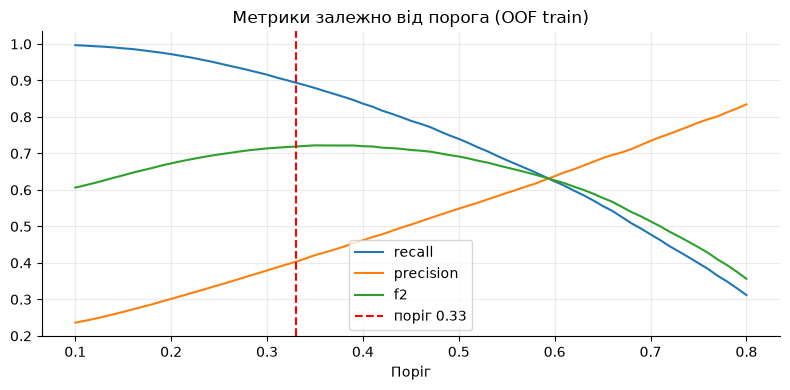

In [5]:
run_full = cv_run(best, X_train, perm=True)
best_t, threshold_table = choose_threshold(run_full["oof_y"], run_full["oof_proba"])

row = threshold_table[threshold_table["threshold"] == best_t].iloc[0]
print(f"Обраний поріг: {best_t:.2f} | Recall {row['recall']:.3f} | Precision {row['precision']:.3f}")
base_rate = run_full["oof_y"].mean()
if row["precision"] < 1.5 * base_rate:
    print(f"⚠️ Precision лише в {row['precision']/base_rate:.2f}× вища за частку дощових днів ({base_rate:.3f}): "
          "модель майже завжди прогнозує дощ. Подумайте про більший MIN_PRECISION.")

fig, ax = plt.subplots(figsize=(8, 4))
for col in ["recall", "precision", "f2"]:
    ax.plot(threshold_table["threshold"], threshold_table[col], label=col)
ax.axvline(best_t, color="red", linestyle="--", label=f"поріг {best_t:.2f}")
ax.set(xlabel="Поріг", title="Метрики залежно від порога (OOF train)")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Оцінка на test: модель з усіма ознаками (еталон)

In [6]:
test_proba_full = best.predict_proba(X_test)[:, 1]
ref_table = pd.DataFrame([test_metrics(test_proba_full, 0.50), test_metrics(test_proba_full, best_t)],
                         index=["поріг 0.50", f"поріг {best_t:.2f}"])
display(ref_table.round(3))

,threshold,Accuracy,Precision,Recall,F1,F2,ROC-AUC,PR-AUC
поріг 0.50,0.50,0.794,0.540,0.756,0.630,0.700,0.863,0.7
поріг 0.33,0.33,0.659,0.397,0.903,0.551,0.719,0.863,0.7


## 6. Перевірка на витоки

In [7]:
AUC_LEAK, AUC_SUSPECT = 0.90, 0.80
audit = []


def add(check, feature, value, status):
    audit.append({"перевірка": check, "ознака": feature, "значення": value, "статус": status})


for c in X_train.columns:
    if re.search(r"tomorrow|target|label", c, re.I):
        add("назва колонки", c, np.nan, "ВИТІК")
    elif re.search(r"next|future|after|^(date|year|month|day|time)", c, re.I):
        add("назва колонки", c, np.nan, "ПІДОЗРА")

dates = pd.to_datetime(train["Date"])
gap_days = (pd.to_datetime(test["Date"]).min() - dates.max()).days
add("хронологія: train → test (днів)", "—", gap_days, "OK" if gap_days >= 1 else "ВИТІК")
for i, (tr, va) in enumerate(cv, 1):
    overlap = (dates.iloc[tr].max() - dates.iloc[va].min()).days
    add(f"хронологія: фолд {i} (днів перекриття)", "—", overlap, "OK" if overlap <= 0 else "ВИТІК")

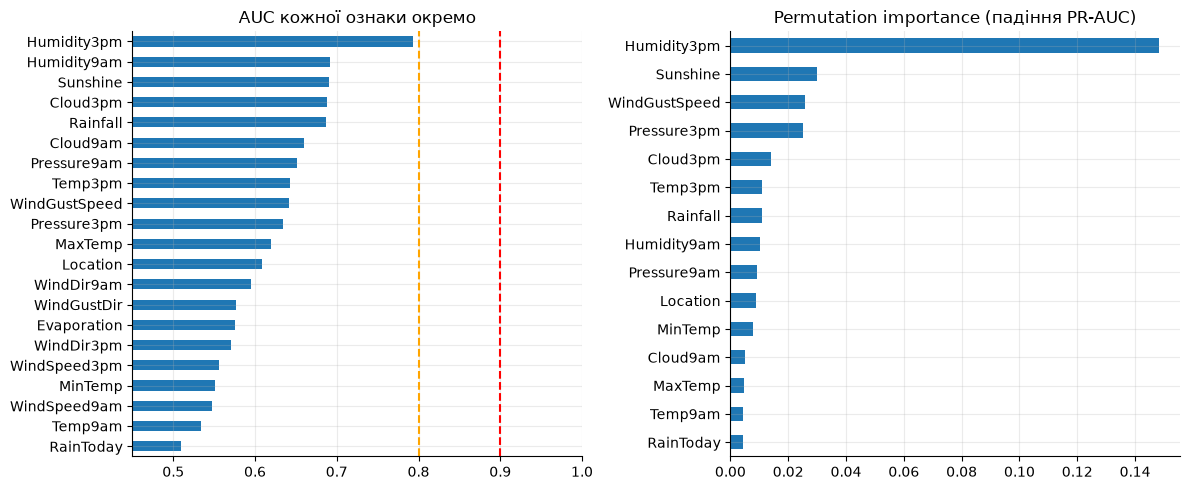

Топова ознака: Humidity3pm | частка 44% | AUC на перемішаних мітках 0.495


In [8]:
y_arr = y_train.to_numpy()


def single_feature_auc(col):
    x = X_train[col]
    if pd.api.types.is_numeric_dtype(x):
        groups = pd.qcut(x, 20, duplicates="drop").astype(str)
    else:
        groups = x.astype(str)
    aucs = []
    for tr, va in cv:
        rate = pd.Series(y_arr[tr]).groupby(groups.iloc[tr].to_numpy()).mean()
        score = groups.iloc[va].map(rate).fillna(y_arr[tr].mean()).to_numpy()
        aucs.append(roc_auc_score(y_arr[va], score))
    return float(np.mean(aucs))


single_auc = pd.Series({c: single_feature_auc(c) for c in X_train.columns}).sort_values(ascending=False)
for c, a in single_auc.items():
    add("AUC однієї ознаки", c, a, "ВИТІК" if a >= AUC_LEAK else "ПІДОЗРА" if a >= AUC_SUSPECT else "OK")

perm_mean = run_full["perm"].mean().sort_values(ascending=False)
top_feature = perm_mean.index[0]
positive = perm_mean.clip(lower=0)
share = positive.iloc[0] / positive.sum()
ratio = positive.iloc[0] / max(positive.iloc[1], 1e-9)
add("частка топової ознаки в permutation importance", top_feature, share, "ПІДОЗРА" if share > 0.5 else "OK")
add("топова / друга за важливістю", top_feature, ratio, "ПІДОЗРА" if ratio > 3 else "OK")

tr, va = cv[-1]
shuffled = np.random.RandomState(SEED).permutation(y_arr[tr])
m = clone(best).fit(X_train.iloc[tr], shuffled)
auc_shuffled = roc_auc_score(y_arr[va], m.predict_proba(X_train.iloc[va])[:, 1])
del m
gc.collect()
add("перемішані мітки (очікується ≈ 0.5)", "—", auc_shuffled, "OK" if auc_shuffled < 0.55 else "ПІДОЗРА")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
single_auc.sort_values().plot(kind="barh", ax=axes[0])
axes[0].axvline(AUC_SUSPECT, color="orange", linestyle="--")
axes[0].axvline(AUC_LEAK, color="red", linestyle="--")
axes[0].set(xlim=(0.45, 1.0), title="AUC кожної ознаки окремо")
perm_mean.head(15).sort_values().plot(kind="barh", ax=axes[1])
axes[1].set(title="Permutation importance (падіння PR-AUC)")
plt.tight_layout()
plt.show()
print(f"Топова ознака: {top_feature} | частка {share:.0%} | AUC на перемішаних мітках {auc_shuffled:.3f}")

## 7. Абляційний експеримент

In [9]:
others = [c for c in X_train.columns if c != top_feature]
pr_all = run_full["pr_auc"]
pr_without = cv_run(best, neutralize(X_train, [top_feature]))["pr_auc"]
pr_only = cv_run(best, neutralize(X_train, others))["pr_auc"]

ablation = pd.DataFrame({"PR-AUC (CV)": [pr_all, pr_without, pr_only]},
                        index=["Усі ознаки", f"Без {top_feature}", f"Лише {top_feature}"])
display(ablation.round(3))

drop = pr_all - pr_without
solo = pr_only / pr_all
print(f"Падіння без {top_feature}: {drop:.3f} | лише {top_feature} дає {solo:.0%} від повної моделі")
add("абляція: падіння PR-AUC без топової", top_feature, drop, "ПІДОЗРА" if drop >= 0.10 else "OK")
add("абляція: частка PR-AUC лише від топової", top_feature, solo,
    "ВИТІК" if solo >= 0.95 else "ПІДОЗРА" if solo >= 0.85 else "OK")

,PR-AUC (CV)
Усі ознаки,0.693
Без Humidity3pm,0.645
Лише Humidity3pm,0.565


Падіння без Humidity3pm: 0.048 | лише Humidity3pm дає 81% від повної моделі


### 7.1 Підсумок перевірок

In [10]:
audit_df = pd.DataFrame(audit)
flagged = audit_df[audit_df["статус"] != "OK"]
display(flagged.sort_values("статус", ascending=False).round(3) if len(flagged)
        else pd.DataFrame({"результат": ["усі перевірки пройдено"]}))

is_feature = audit_df["ознака"].isin(X_train.columns)

MANUAL_DROP = []
MANUAL_KEEP = []

leaky = set(audit_df[(audit_df["статус"] == "ВИТІК") & is_feature]["ознака"])
excluded = sorted((leaky | set(MANUAL_DROP)) - set(MANUAL_KEEP))

,перевірка,ознака,значення,статус
27,топова / друга за важливістю,Humidity3pm,4.956,ПІДОЗРА


## 8. Відбір ознак

In [11]:
MIN_IMPORTANCE = 5e-4
TOLERANCE = 0.003
min_folds = max(1, len(cv) - 1)

ref = cv_run(best, neutralize(X_train, excluded), perm=True) if excluded else run_full
perm = ref["perm"]

table = pd.DataFrame({"perm_mean": perm.mean(), "perm_std": perm.std(),
                      "додатних фолдів": (perm > 0).sum()}).sort_values("perm_mean", ascending=False)
weak = [c for c in table.index if c not in excluded
        and (table.loc[c, "perm_mean"] <= MIN_IMPORTANCE or table.loc[c, "додатних фолдів"] < min_folds)]

final_drop, final_run = list(excluded), ref
if weak:
    sel = cv_run(best, neutralize(X_train, excluded + weak))
    delta = sel["pr_auc"] - ref["pr_auc"]
    print(f"PR-AUC відібраної моделі проти еталона: {delta:+.4f} (допуск −{TOLERANCE})")
    if delta >= -TOLERANCE:
        final_drop, final_run = excluded + weak, sel
    else:
        print("Відбір погіршує якість — лишаємо еталонний набір.")

table["рішення"] = ["прибрано (витік)" if c in excluded else "прибрано (слабка)" if c in final_drop else "залишено"
                    for c in table.index]
display(table.round(4))
selected = [c for c in X_train.columns if c not in final_drop]
print(f"Залишилось {len(selected)} з {X_train.shape[1]} ознак; прибрано: {final_drop or 'нічого'}")

,perm_mean,perm_std,додатних фолдів,рішення
Humidity3pm,0.1481,0.0124,4,залишено
Sunshine,0.0299,0.0060,4,залишено
WindGustSpeed,0.0258,0.0013,4,залишено
Pressure3pm,0.0252,0.0054,4,залишено
Cloud3pm,0.0139,0.0027,4,залишено
Temp3pm,0.0110,0.0010,4,залишено
Rainfall,0.0108,0.0029,4,залишено
Humidity9am,0.0103,0.0028,4,залишено
Pressure9am,0.0092,0.0017,4,залишено
Location,0.0088,0.0008,4,залишено


Залишилось 21 з 21 ознак; прибрано: нічого


## 9. Фінальна модель: поріг і оцінка на test

,threshold,Accuracy,Precision,Recall,F1,F2,ROC-AUC,PR-AUC
Усі ознаки,0.33,0.659,0.397,0.903,0.551,0.719,0.863,0.7
Фінальна модель,0.33,0.659,0.397,0.903,0.551,0.719,0.863,0.7



Звіт класифікації фінальної моделі:
              precision    recall  f1-score   support

     No rain       0.95      0.59      0.73     13280
        Rain       0.40      0.90      0.55      4006

    accuracy                           0.66     17286
   macro avg       0.67      0.74      0.64     17286
weighted avg       0.82      0.66      0.68     17286



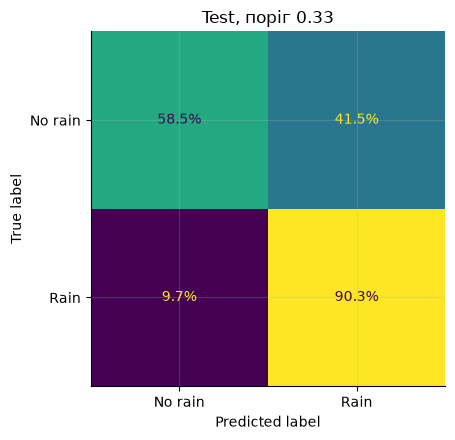

In [12]:
neutral_vals = neutral_values(final_drop)
Xtr_final, Xte_final = neutralize(X_train, final_drop), neutralize(X_test, final_drop)

if final_drop:
    final_model = clone(best).fit(Xtr_final, y_train)
else:
    final_model = best

final_t, _ = choose_threshold(final_run["oof_y"], final_run["oof_proba"])
final_proba = final_model.predict_proba(Xte_final)[:, 1]

compare = pd.DataFrame([test_metrics(test_proba_full, best_t), test_metrics(final_proba, final_t)],
                       index=["Усі ознаки", "Фінальна модель"])
display(compare.round(3))

print("\nЗвіт класифікації фінальної моделі:")
final_pred = (final_proba >= final_t).astype(int)
print(classification_report(y_test, final_pred, labels=[0, 1],
                            target_names=["No rain", "Rain"], zero_division=0))
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, final_pred, labels=[0, 1],
                                        display_labels=["No rain", "Rain"],
                                        normalize="true", values_format=".1%", ax=ax, colorbar=False)
ax.set_title(f"Test, поріг {final_t:.2f}")
plt.tight_layout()
plt.show()

## 10. Збереження

In [13]:
artifact = {
    "model": final_model,
    "threshold": final_t,
    "target": "RainTomorrow",
    "dropped_features": final_drop,
    "neutral_values": neutral_vals,
    "audit": audit_df,
}
joblib.dump(artifact, "rf_rain_model.joblib")
print("Збережено: rf_rain_model.joblib")

Збережено: rf_rain_model.joblib
